# **Lab 7(A) - Laplacian Filter**

**Course:** ARTI 403 – Image Processing

**Images used** (in the `Images/` folder):
- `moon.jpg` – the moon image used in the lab code

In [1]:
import cv2
import numpy as np

from IPython.display import Image, display
from matplotlib import pyplot as plt

plt.rc('text', usetex=False)

## Apply Laplacian Filter on Image to get Sharp Image
### Method 1 – Manual Laplacian kernel with `cv2.filter2D`

**Note:** `img` and `laplacian_abs` are both `uint8`. Adding them with `+` wraps around after 255 (for example 250 + 10 = 4), which creates black dots on the bright edges. `cv2.add` saturates at 255 instead, so it is used for the final image.

Image shape: (438, 401) | dtype: uint8


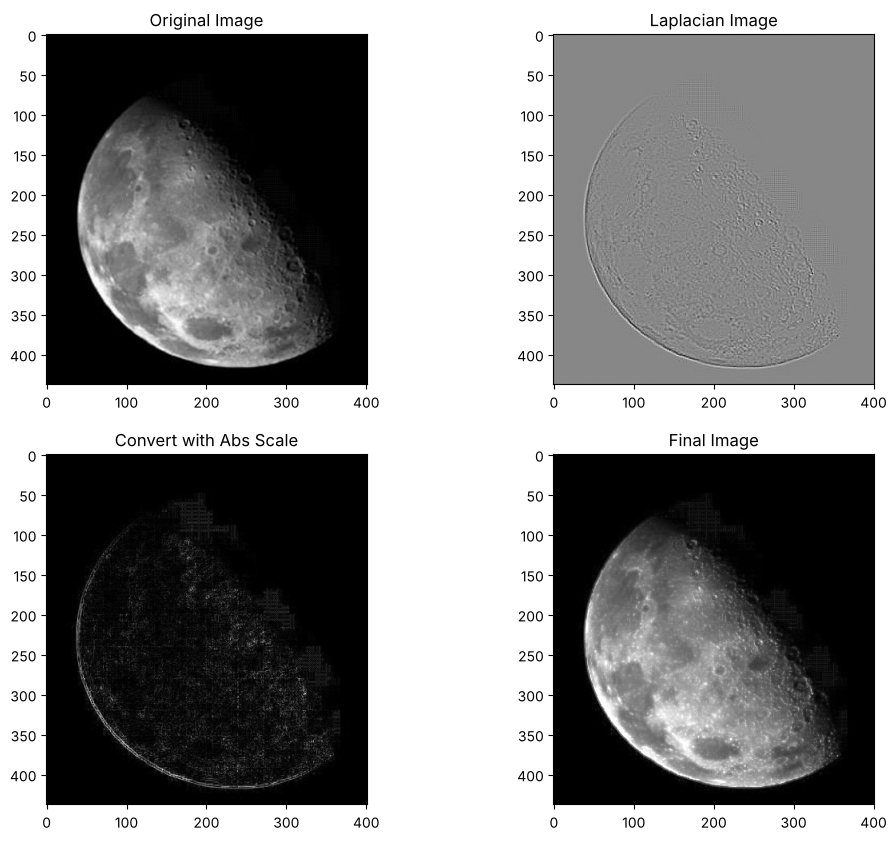

In [2]:
# ================ ( Laplacian Filter ) ===================

# 0. Image file path
imgFile = "Images/moon.jpg"

# 1. Load image and convert to grayscale
img = cv2.imread(imgFile, 0)
print('Image shape:', img.shape, '| dtype:', img.dtype)

# 2. Manually define the Laplacian Kernel
# This is the standard 3x3 kernel that detects horizontal and vertical edges
manual_kernel = np.array([
    [0,  1,  0],
    [1, -4,  1],
    [0,  1,  0]
], dtype=np.float32)

# 3. Apply the filter using filter2D
# Use cv2.CV_64F to avoid clipping negative values
laplacian_manual = cv2.filter2D(img, cv2.CV_64F, manual_kernel)

# 4. Take absolute value and convert back to 8-bit (0-255)
laplacian_abs = cv2.convertScaleAbs(laplacian_manual)

# 5. Add Laplacian to the original (saturating add, no uint8 overflow)
finalImage = cv2.add(img, laplacian_abs)

# 6. Display images
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img, cmap='gray'), plt.title('Original Image')
plt.subplot(222), plt.imshow(laplacian_manual, cmap='gray'), plt.title('Laplacian Image')
plt.subplot(223), plt.imshow(laplacian_abs, cmap='gray'), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(finalImage, cmap='gray'), plt.title('Final Image')
plt.show()

### Why `cv2.add` instead of `+`

Pixels that overflow with "+": 541


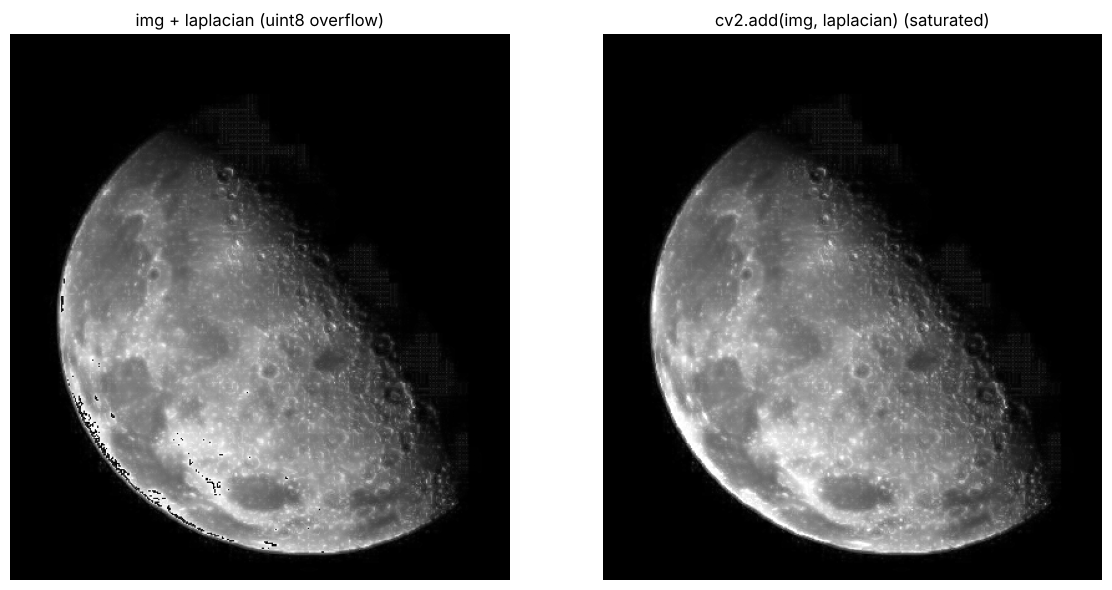

In [3]:
wrong = img + laplacian_abs            # numpy uint8 addition wraps around
overflow = (img.astype(int) + laplacian_abs) > 255
print('Pixels that overflow with "+":', overflow.sum())

plt.figure(figsize=(12, 6))
plt.subplot(121), plt.imshow(wrong, cmap='gray'), plt.title('img + laplacian (uint8 overflow)'), plt.axis('off')
plt.subplot(122), plt.imshow(finalImage, cmap='gray'), plt.title('cv2.add(img, laplacian) (saturated)'), plt.axis('off')
plt.tight_layout(); plt.show()

**Observation:** with `+`, bright pixels next to strong edges overflow and turn black (the dark dots on the lit edge of the moon). `cv2.add` clips them at 255, so the final image has no artifacts.

### Method 2 – Gaussian blur + `cv2.Laplacian`
A small Gaussian blur before the Laplacian reduces noise, so tiny details are not detected as edges.

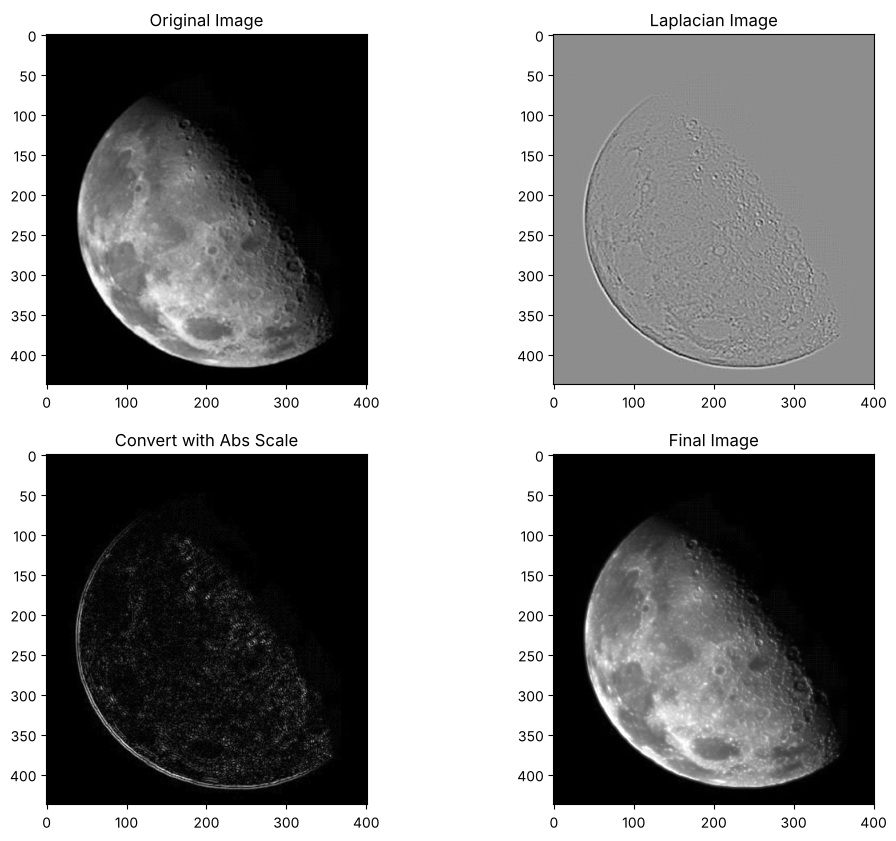

In [4]:
# ================== ( Laplacian Filter ) ===============

# 1. Apply Gaussian Blur to reduce noise
blurred = cv2.GaussianBlur(img, (3, 3), 0)

# 2. Apply the Laplacian Algorithm
# Use CV_64F to capture both positive and negative gradients
laplacian = cv2.Laplacian(blurred, cv2.CV_64F)

# 3. Convert back to 8-bit image to view it properly
laplacian_8bit = cv2.convertScaleAbs(laplacian)

# 4. Adding Laplacian and original image (saturating add)
finalImage2 = cv2.add(img, laplacian_8bit)

# 5. Display images
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img, cmap='gray'), plt.title('Original Image')
plt.subplot(222), plt.imshow(laplacian, cmap='gray'), plt.title('Laplacian Image')
plt.subplot(223), plt.imshow(laplacian_8bit, cmap='gray'), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(finalImage2, cmap='gray'), plt.title('Final Image')
plt.show()

**Observation:** the Laplacian image after Gaussian blur is cleaner, with fewer small responses in the dark background, while the crater edges are still detected.

## 4-neighbour vs. 8-neighbour Laplacian kernel
The 8-neighbour kernel also includes the diagonal neighbours, so it also detects diagonal edges and gives a stronger response.

Mean edge response  4-neighbour: 4.13 | 8-neighbour: 11.20


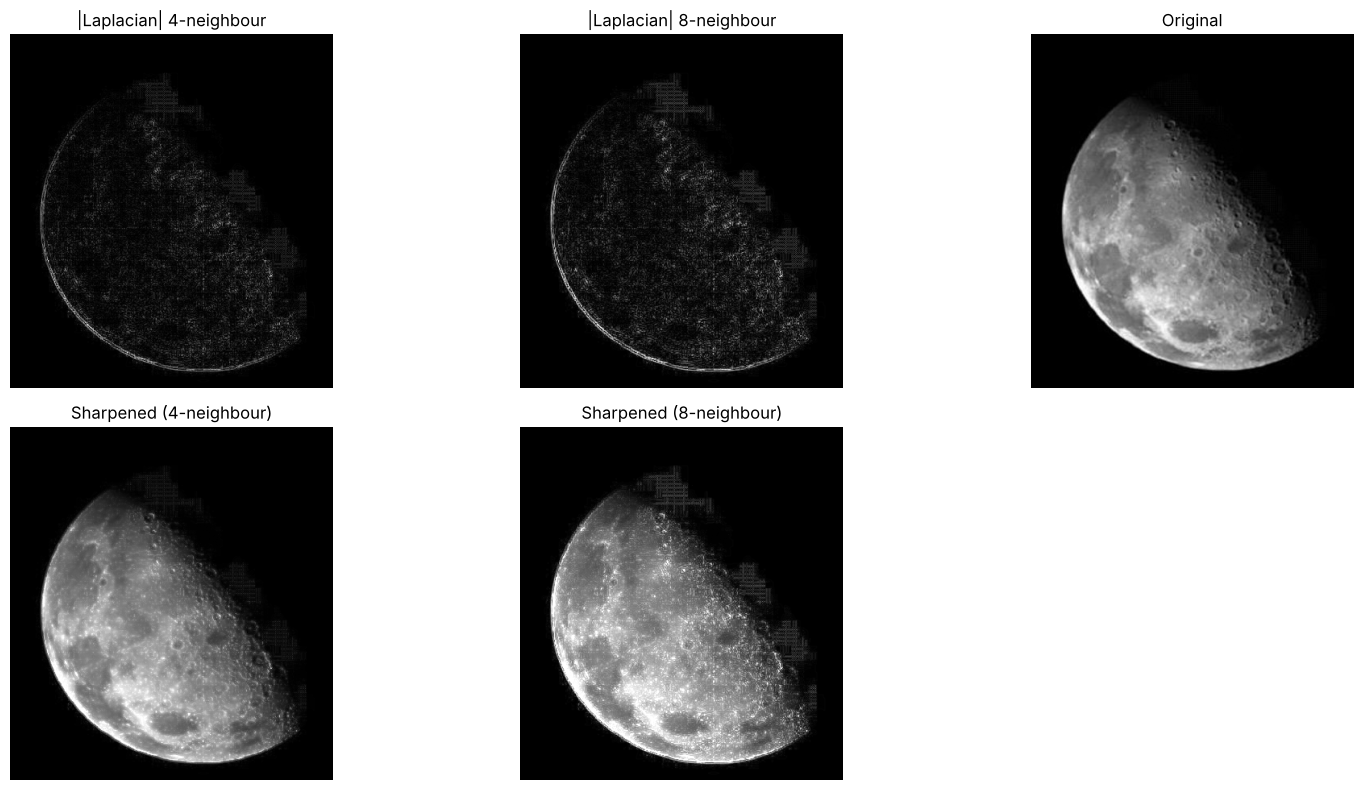

In [5]:
kernel_4 = np.array([[0,  1, 0],
                     [1, -4, 1],
                     [0,  1, 0]], dtype=np.float32)

kernel_8 = np.array([[1,  1, 1],
                     [1, -8, 1],
                     [1,  1, 1]], dtype=np.float32)

lap4 = cv2.convertScaleAbs(cv2.filter2D(img, cv2.CV_64F, kernel_4))
lap8 = cv2.convertScaleAbs(cv2.filter2D(img, cv2.CV_64F, kernel_8))
print('Mean edge response  4-neighbour: %.2f | 8-neighbour: %.2f' % (lap4.mean(), lap8.mean()))

plt.figure(figsize=(16, 8))
plt.subplot(231), plt.imshow(lap4, cmap='gray'), plt.title('|Laplacian| 4-neighbour')
plt.subplot(232), plt.imshow(lap8, cmap='gray'), plt.title('|Laplacian| 8-neighbour')
plt.subplot(233), plt.imshow(img, cmap='gray'), plt.title('Original')
plt.subplot(234), plt.imshow(cv2.add(img, lap4), cmap='gray'), plt.title('Sharpened (4-neighbour)')
plt.subplot(235), plt.imshow(cv2.add(img, lap8), cmap='gray'), plt.title('Sharpened (8-neighbour)')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout(); plt.show()

**Observation:** the 8-neighbour kernel gives a stronger edge response (higher mean), so its sharpened image has more contrast on the crater rims.

## Sharpening with the standard formula: g = f − ∇²f
The kernels above have a **negative centre**, so the standard sharpening formula subtracts the Laplacian: **g(x, y) = f(x, y) − ∇²f(x, y)**. This keeps the sign of the Laplacian, so one side of each edge gets darker and the other side brighter, instead of only adding brightness as with the absolute value.

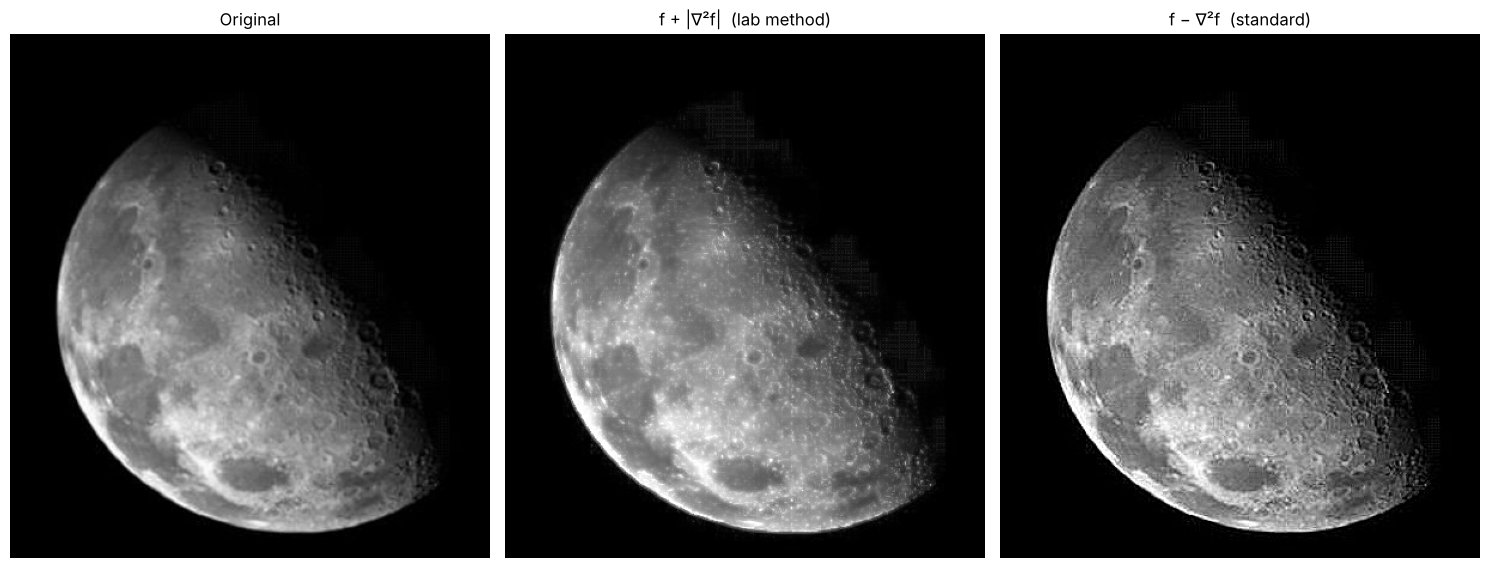

In [6]:
img_float = img.astype(np.float64)
lap = cv2.filter2D(img_float, cv2.CV_64F, kernel_4)
sharpened_std = np.clip(img_float - lap, 0, 255).astype(np.uint8)

plt.figure(figsize=(15, 6))
plt.subplot(131), plt.imshow(img, cmap='gray'), plt.title('Original')
plt.subplot(132), plt.imshow(finalImage, cmap='gray'), plt.title('f + |∇²f|  (lab method)')
plt.subplot(133), plt.imshow(sharpened_std, cmap='gray'), plt.title('f − ∇²f  (standard)')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout(); plt.show()

**Observation:** the standard formula gives a sharper and more natural result: edges get both a dark and a bright side, which increases local contrast. Adding the absolute value only brightens the edges.

## Conclusion
- The Laplacian is a second-derivative filter that detects edges. Adding it to (or, with a negative-centre kernel, subtracting it from) the original image sharpens the image.
- When working with `uint8` images, use `cv2.add` or convert to float and clip, otherwise values wrap around after 255.
- The 8-neighbour kernel responds to diagonal edges too, so it sharpens more than the 4-neighbour kernel.
- The Laplacian amplifies noise, so smoothing first (the Gaussian blur in Method 2) gives a cleaner edge map.